In [71]:
import numpy as np
import matplotlib.pyplot as plt

In [72]:
wind= float(input("Enter the wind speed in units of cs_inf (0 = spherical Bondi): "))
# Domain construction
rmin= float(input("Enter the minimum radius: "))
rmax= float(input("Enter the maximum radius: "))
Nr= int(input("Enter the number of radial points: "))
Nphi= int(input("Enter the number of theta points: "))
dr= (rmax-rmin)/Nr
dphi= np.pi/Nphi
# cell centers arrays 
r= np.linspace(rmin+dr/2, rmax-dr/2, Nr)
phi= np.linspace(dphi/2, np.pi-dphi/2, Nphi)
# faces arrays n
rf= np.linspace(rmin, rmax, Nr+1)
phif= np.linspace(0, np.pi, Nphi+1)
# 2D arrays (Nr, Nth) by broadcasting
R= r[:, None]*np.ones(Nphi)[None, :]
Phi= np.ones(Nr)[:, None]*phi[None, :]
# exact integrals over one cell:  dr3 = int r^2 dr ,  dcos = int sin(theta) dtheta
dcos = np.cos(phif[:-1]) - np.cos(phif[1:])      # (Nth,)
dr3  = (rf[1:]**3 - rf[:-1]**3)/3.0            # (Nr,)

V    = dr3[:, None]*dcos[None, :]              # (Nr, Nth)
Ar   = (rf**2)[:, None]*dcos[None, :]          # (Nr+1, Nth)
Aphi = dr3[:, None]*np.sin(phif)[None, :]       # (Nr, Nth+1)           # volume of the cells      (Nr, Nth)


In [73]:
# intial conditions 
# constants 
gamma=5/3
G=1
M=1
rho_inf=1
cs_inf=1
P_inf= rho_inf*cs_inf**2/gamma
# Intial conditions
rho = np.ones((Nr, Nphi))*rho_inf
ur = wind*np.cos(phi)[None, :]
uphi = wind*np.sin(phi)[None, :]
p = np.ones((Nr, Nphi))*P_inf
# Ensure all state variables use the same orientation: (Nr, Nphi)

E = p / (gamma - 1) + 0.5 * rho * (ur**2 + uphi**2)
U = np.zeros((4, Nr, Nphi))
U[0] = rho
U[1] = rho*ur
U[2] = rho*uphi
U[3] = E

In [74]:
#  funtion to retain the primary variable 
def Initial(U):
    rho=U[0]
    ur=U[1]/rho
    uphi=U[2]/rho
    E=U[3]
    p=(gamma-1)*(E-0.5*rho*(ur**2+ uphi**2))
    return rho, ur, uphi, p

In [75]:
#  flux in radial direction 
def flux_r(U):
    rho , ur, uphi, p = Initial(U)
    F_r= np.zeros_like(U)
    F_r[0]= rho*ur
    F_r[1]= rho*ur**2+ p
    F_r[2]= rho*ur*uphi
    F_r[3]=(U[3]+p)*ur
    return F_r

In [76]:
# flux in phi direction 
def flux_phi(U):
    rho , ur, uphi, p = Initial(U)
    F_phi= np.zeros_like(U)
    F_phi[0]= rho*uphi
    F_phi[1]= rho*ur*uphi
    F_phi[2]= rho*uphi**2+ p
    F_phi[3]=(U[3]+p)*uphi
    return F_phi

In [77]:
def HLLC_r(Ul, Ur):
    rhol, ul, vtl, pl = Initial(Ul)
    rhor, ur, vtr, pr = Initial(Ur)
    ## fluxes
    Fl = flux_r(Ul)
    Fr = flux_r(Ur)
    ## energy
    El = Ul[3]
    Er = Ur[3]
    # speed of sound
    cl = np.sqrt(gamma*pl/rhol)
    cr = np.sqrt(gamma*pr/rhor)
 
    # wave speed
    Sl = np.minimum(ul-cl, ur-cr)
    sr = np.maximum(ul+cl, ur+cr)
 
    # contact wave speed
    Sstar = (pr-pl + rhol*ul*(Sl-ul) - rhor*ur*(sr-ur))/(rhol*(Sl-ul) - rhor*(sr-ur))

    Ustar_l = rhol*(Sl-ul)/(Sl-Sstar)*np.array([np.ones_like(Sstar), Sstar, vtl,
                                                El/rhol + (Sstar-ul)*(Sstar + pl/(rhol*(Sl-ul)))])
    Ustar_r = rhor*(sr-ur)/(sr-Sstar)*np.array([np.ones_like(Sstar), Sstar, vtr,
                                                Er/rhor + (Sstar-ur)*(Sstar + pr/(rhor*(sr-ur)))])
    Fstar_l = Fl + Sl*(Ustar_l - Ul)
    Fstar_r = Fr + sr*(Ustar_r - Ur)
 
   
    return np.where(Sl >= 0, Fl,
           np.where(Sstar >= 0, Fstar_l,
           np.where(sr >= 0, Fstar_r, Fr)))
 
    


In [78]:
def HLLC_phi(Ul, Ur):
    rhol, vrl, ul, pl = Initial(Ul)       
    rhor, vrr, ur, pr = Initial(Ur)
    ## fluxes
    Fl = flux_phi(Ul)
    Fr = flux_phi(Ur)
    ## energy
    El = Ul[3]
    Er = Ur[3]
    # speed of sound
    cl = np.sqrt(gamma*pl/rhol)
    cr = np.sqrt(gamma*pr/rhor)
 
    # wave speed
    Sl = np.minimum(ul-cl, ur-cr)
    sr = np.maximum(ul+cl, ur+cr)
 
    # contact wave speed
    Sstar = (pr-pl + rhol*ul*(Sl-ul) - rhor*ur*(sr-ur))/(rhol*(Sl-ul) - rhor*(sr-ur))
 
    Ustar_l = rhol*(Sl-ul)/(Sl-Sstar)*np.array([np.ones_like(Sstar), vrl, Sstar,
                                                El/rhol + (Sstar-ul)*(Sstar + pl/(rhol*(Sl-ul)))])
    Ustar_r = rhor*(sr-ur)/(sr-Sstar)*np.array([np.ones_like(Sstar), vrr, Sstar,
                                                Er/rhor + (Sstar-ur)*(Sstar + pr/(rhor*(sr-ur)))])
    Fstar_l = Fl + Sl*(Ustar_l - Ul)
    Fstar_r = Fr + sr*(Ustar_r - Ur)
 
    return np.where(Sl >= 0, Fl,
           np.where(Sstar >= 0, Fstar_l,
           np.where(sr >= 0, Fstar_r, Fr)))

In [79]:
rho_floor = 1e-6                      
p_floor   = 1e-6                      

g_r = -G*M/R**2                       
p_amb  = rho_inf*cs_inf**2/gamma
vr_amb =  wind*np.cos(phi)
vt_amb = -wind*np.sin(phi)
U_amb  = np.array([rho_inf*np.ones(Nphi), vr_amb, vt_amb, p_amb*np.ones(Nphi)])  

In [80]:
def pad(U):
    Up = np.empty((4, Nr+2, Nphi+2))
    Up[:, 1:-1, 1:-1] = U

    # theta axis: mirror, flip v_theta
    Up[:, :, 0]  = Up[:, :, 1]
    Up[:, :, -1] = Up[:, :, -2]
    Up[2, :, 0]  *= -1
    Up[2, :, -1] *= -1

    # inner radius: zero-gradient (outflow)
    Up[:, 0, 1:-1] = U[:, 0, :]

    # outer radius: ambient where gas flows in (v_r_amb <= 0), zero-gradient otherwise
    inflow = (vr_amb <= 0.0)[None, :]
    Up[:, -1, 1:-1] = np.where(inflow, U_amb, U[:, -1, :])

    # corners (not used by the face fluxes, but keep finite)
    Up[:, 0, 0]  = Up[:, 0, 1];  Up[:, 0, -1]  = Up[:, 0, -2]
    Up[:, -1, 0] = Up[:, -1, 1]; Up[:, -1, -1] = Up[:, -1, -2]
    return Up

In [81]:
CFL = 0.4
t = 0.0
t_end = 0.2

while t < t_end:
    rho, vr, vt, p = Initial(U)
    a = np.sqrt(gamma*p/rho)
    # Fix the grid orientation to match the state arrays: (Nr, Nphi)
    g_r = -G * M / R**2

    dt = CFL / np.max((np.abs(vr) + a) / dr + (np.abs(vt) + a) / (R * dphi))
    dt = min(dt, 0.1*np.sqrt(dr/np.max(np.abs(g_r))))        # gravity limit on dt
    if t + dt > t_end:
        dt = t_end - t

    Up = pad(U)                  # ghost cells: inner outflow, outer ambient, theta-axis mirror

    F_interface_r     = HLLC_r(Up[:, :-1, 1:-1], Up[:, 1:, 1:-1])        # (4, Nr+1, Nth)
    F_interface_phi = HLLC_phi(Up[:, 1:-1, :-1], Up[:, 1:-1, 1:])    # (4, Nr, Nth+1)

    S = np.zeros_like(U)
    S[1] = rho*g_r + p*(Ar[1:, :] - Ar[:-1, :])/V + rho*vt**2/R
    S[2] = p*(Aphi[:, 1:] - Aphi[:, :-1])/V - rho*vr*vt/R
    S[3] = rho*vr*g_r

    U_new = U - (dt/V)*((Ar[1:, :]*F_interface_r[:, 1:, :] - Ar[:-1, :]*F_interface_r[:, :-1, :]) +
                          (Aphi[:, 1:]*F_interface_phi[:, :, 1:] - Aphi[:, :-1]*F_interface_phi[:, :, :-1])) + dt*S

    U_new[0] = np.maximum(U_new[0], rho_floor)
    kin = 0.5*(U_new[1]**2 + U_new[2]**2)/U_new[0]
    U_new[3] = np.maximum(U_new[3], kin + p_floor/(gamma-1))

    if not np.all(np.isfinite(U_new)):
        raise RuntimeError(f"NaN at t={t:.4f}")

    U = U_new
    t += dt

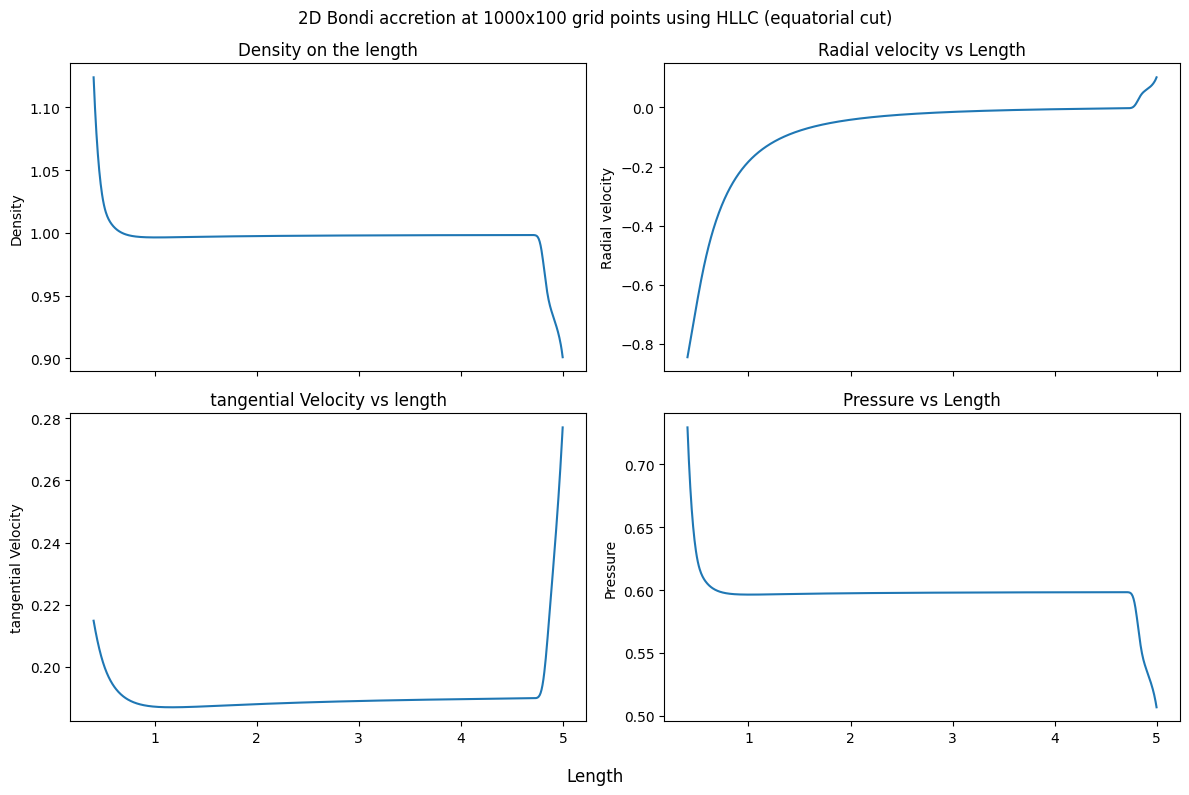

In [82]:
j= Nphi//2
rho, vr, vt, p = Initial(U)
fig,ax=plt.subplots(2, 2, figsize=(12, 8), sharex=True)
 
ax[0,0].plot(r, rho[:, j])
ax[0, 0].set_ylabel("Density")
ax[0,0].set_title("Density on the length")
 

ax[0, 1].plot(r, vr[:, j])
ax[0, 1].set_ylabel("Radial velocity")
ax[0, 1].set_title("Radial velocity vs Length")

ax[1, 0].plot(r, vt[:,j])
ax[1 ,0].set_ylabel("tangential Velocity")
ax[1, 0].set_title (" tangential Velocity vs length ")
 
ax[1, 1].plot(r, p[:, j])
ax[1, 1].set_ylabel("Pressure")
ax[1, 1].set_title("Pressure vs Length")
fig.supxlabel("Length")
 
fig.suptitle(f"2D Bondi accretion at {Nr}x{Nphi} grid points using HLLC (equatorial cut)")
fig.tight_layout()
plt.show()

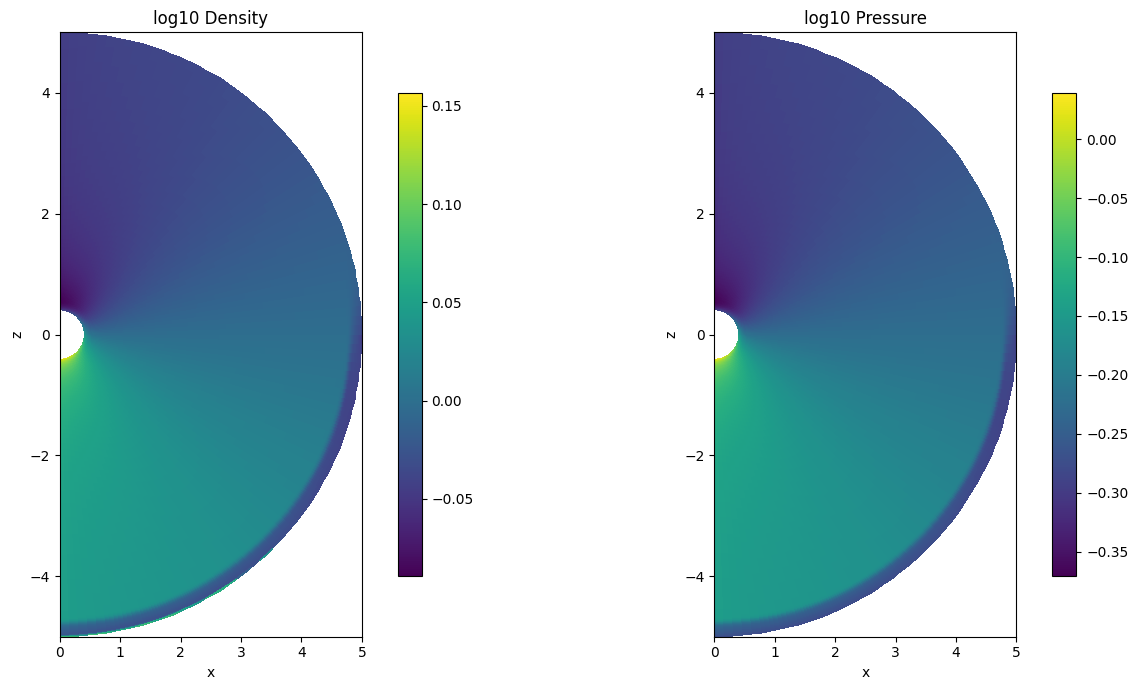

In [83]:
Xf= rf[:, None]*np.sin(phif)[None, :]
Zf= rf[:, None]*np.cos(phif)[None, :]
fig,ax=plt.subplots(1, 2, figsize=(14, 7))
im0=ax[0].pcolormesh(Xf, Zf, np.log10(rho), shading="flat")
ax[0].set_title("log10 Density")
im1=ax[1].pcolormesh(Xf, Zf, np.log10(p), shading="flat")
ax[1].set_title("log10 Pressure")
for a_, im in zip(ax, (im0, im1)):
    a_.set_aspect("equal")
    a_.set_xlabel("x")
    a_.set_ylabel("z")
    plt.colorbar(im, ax=a_, shrink=0.8)
fig.tight_layout()
plt.show()

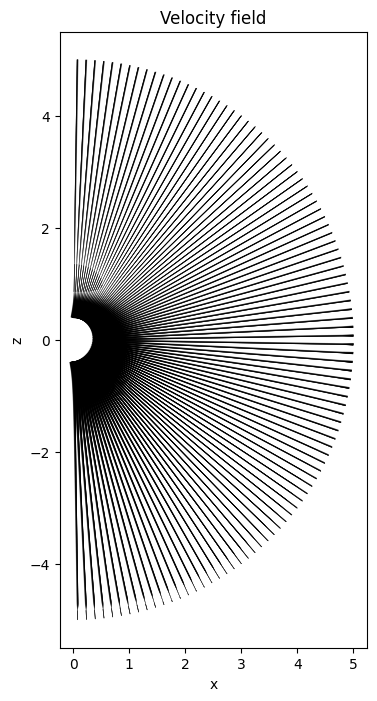

In [84]:
# cell-centered coordinates for the velocity field
Xc = r[:, None] * np.sin(phi)[None, :]
Zc = r[:, None] * np.cos(phi)[None, :]

# quiver needs matching shapes: Xc,Zc,vr,vt all (Nr, Nphi)
fig, ax = plt.subplots(figsize=(8, 8))
q = ax.quiver(Xc, Zc, vr, vt, pivot='middle', scale=35)
ax.set_aspect('equal')
ax.set_xlabel('x')
ax.set_ylabel('z')
ax.set_title('Velocity field')
plt.show()